In [1]:
# Import necessary libraries
import doubletdetection
import scanpy as sc
import pandas as pd
import anndata as ad
import numpy as np
import os
from tqdm import tqdm
import seaborn as sns
from matplotlib import pyplot as plt
import matplotlib as mpl
import harmonypy as hm
from datetime import datetime

In [11]:
# For cleaner output
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Define the directory containing the sample directories
base_dir = "/scratch/svc_td_regene/eye_retinopathy/scs_data"
os.chdir("/scratch/svc_td_regene/eye_retinopathy")
base_dir

date = datetime.today().strftime('%Y%m%d')
date

'20261119'

In [12]:
def filter_cells(data, name, verbose=True):
    n_initial = data.shape[0]

    # Doublet detection
    # How does it work specifically?
    clf = doubletdetection.BoostClassifier()

    doublets = clf.fit(data.X).predict()
    doublet_score = clf.doublet_score()
    data.obs["doublet"] = doublets
    data.obs["doublet_score"] = doublet_score
    print(data)

    # MT pct
    data.var["mt"] = data.var_names.str.startswith("MT-")
    sc.pp.calculate_qc_metrics(data, qc_vars=["mt"],
    percent_top=None, log1p=False, inplace=True)
    print(data)
    
    # MT filter
    data = data[data.obs['pct_counts_mt'] < 20, :].copy()
    print(data)
    
    # Filter low gene count
    data = data[(data.obs['n_genes_by_counts'] >= 100)].copy()
    print(data)
    
    # Remove platelets
    if 'PF4' in data.var_names:
        data = data[data[:, 'PF4'].X.toarray().flatten() == 0].copy()
    print(data)
    
    # Remove red blood cells
    if 'HBB' in data.var_names:
        data = data[~(data[:, 'HBB'].X.toarray().flatten() > 1)].copy()
    print(data)

    # Filter out genes expressed in less than 2 cells
    sc.pp.filter_genes(data, min_cells=3)
    print(data)

    # Remove doublets
    data = data[~(data.obs['doublet'] == 1)].copy()
    print(data)

    n_removed = n_initial - data.shape[0]
    if verbose:
        print(f'{name}: Filtered out {n_removed} cells.')
    return data 

In [13]:
samples = ['AF-TD-FAW-1', 'AF-TD-FAW-2','AF-TD-TED-2', 'AF-TTF-1']

adata_dict = {}
for sample in samples:
    adata = sc.read_10x_mtx(f'{base_dir}/{sample}')
    adata.obs['sample'] = sample
    adata_dict[sample] = filter_cells(adata, sample)

adata_dict

  0%|          | 0/10 [00:00<?, ?it/s]

AnnData object with n_obs × n_vars = 1130 × 36601
    obs: 'sample', 'doublet', 'doublet_score'
    var: 'gene_ids', 'feature_types'
AnnData object with n_obs × n_vars = 1130 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 1101 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 1089 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'


  0%|          | 0/10 [00:00<?, ?it/s]

AnnData object with n_obs × n_vars = 1592 × 36601
    obs: 'sample', 'doublet', 'doublet_score'
    var: 'gene_ids', 'feature_types'
AnnData object with n_obs × n_vars = 1592 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 1514 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 1462 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'


  0%|          | 0/10 [00:00<?, ?it/s]

AnnData object with n_obs × n_vars = 5371 × 36601
    obs: 'sample', 'doublet', 'doublet_score'
    var: 'gene_ids', 'feature_types'
AnnData object with n_obs × n_vars = 5371 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 4875 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 4875 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'


  0%|          | 0/10 [00:00<?, ?it/s]

AnnData object with n_obs × n_vars = 1835 × 36601
    obs: 'sample', 'doublet', 'doublet_score'
    var: 'gene_ids', 'feature_types'
AnnData object with n_obs × n_vars = 1835 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 1638 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
AnnData object with n_obs × n_vars = 1637 × 36601
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'


{'AF-TD-FAW-1': AnnData object with n_obs × n_vars = 927 × 16502
     obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
     var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells',
 'AF-TD-FAW-2': AnnData object with n_obs × n_vars = 1382 × 21788
     obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
     var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells',
 'AF-TD-TED-2': AnnData object with n_obs × n_vars = 4442 × 26009
     obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
     var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells',
 'AF-TTF-1': AnnData object with n_obs × n_v

In [14]:
adata_concat = ad.concat(adata_dict, join='inner')
adata_concat.raw = adata_concat.copy()
adata_concat.transpose()

sc.pp.normalize_total(adata_concat, target_sum=1e4)

sc.pp.log1p(adata_concat)

# save log1p
adata_concat.layers['log1p'] = adata_concat.X.copy()

# Highly variable genes
sc.pp.highly_variable_genes(adata_concat)
adata_concat

# regress out total counts and mt pct
sc.pp.regress_out(adata_concat, ['total_counts', 'pct_counts_mt'])

# Scale
print("Scaling...")
sc.pp.scale(adata_concat)

print("Calculating PCA...")
# PCA
sc.pp.pca(adata_concat, n_comps=50)


Scaling...
Calculating PCA...


In [16]:
print('Running Harmony integration...')
#sc.external.pp.harmony_integrate(adata_concat, key='sample')

# Running harmony without scanpy
pca = adata_concat.obsm['X_pca']
batch_key = 'sample'

harmony_out = hm.run_harmony(pca, adata_concat.obs, batch_key)
z_corr = harmony_out.Z_corr
adata_concat.obsm['X_pca_harmony'] = z_corr

2026-11-19 18:27:40,780 - harmonypy - INFO - Running Harmony (PyTorch on cpu)
2026-11-19 18:27:40,781 - harmonypy - INFO -   Parameters:
2026-11-19 18:27:40,783 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-19 18:27:40,784 - harmonypy - INFO -     max_iter_kmeans: 20
2026-11-19 18:27:40,785 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-11-19 18:27:40,786 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-11-19 18:27:40,787 - harmonypy - INFO -     nclust: 100
2026-11-19 18:27:40,788 - harmonypy - INFO -     block_size: 0.05
2026-11-19 18:27:40,789 - harmonypy - INFO -     lamb: [1. 1. 1. 1.]
2026-11-19 18:27:40,791 - harmonypy - INFO -     theta: [2. 2. 2. 2.]
2026-11-19 18:27:40,792 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-19 18:27:40,793 - harmonypy - INFO -     verbose: True
2026-11-19 18:27:40,794 - harmonypy - INFO -     random_state: 0
2026-11-19 18:27:40,795 - harmonypy - INFO -   Data: 50 PCs × 8377 cells
2026-11-19 18:27:40,796 - harmo

Running Harmony integration...


2026-11-19 18:27:41,003 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-19 18:27:43,580 - harmonypy - INFO - KMeans initialization complete.
2026-11-19 18:27:43,708 - harmonypy - INFO - Iteration 1 of 10
2026-11-19 18:27:44,160 - harmonypy - INFO - Iteration 2 of 10
2026-11-19 18:27:44,538 - harmonypy - INFO - Iteration 3 of 10
2026-11-19 18:27:44,909 - harmonypy - INFO - Iteration 4 of 10
2026-11-19 18:27:45,241 - harmonypy - INFO - Iteration 5 of 10
2026-11-19 18:27:45,613 - harmonypy - INFO - Converged after 5 iterations


In [17]:
print('Creating neighborhood graph...')
sc.pp.neighbors(adata_concat, use_rep='X_pca_harmony')

print('Clustering...')
sc.tl.leiden(adata_concat, resolution=1.0)

print('Creating UMAP...')
sc.tl.umap(adata_concat)

Creating neighborhood graph...
Clustering...
Creating UMAP...


In [18]:
# Add annotations
diabetes_mapping_dict = {
    'AF-TD-FAW-1': 'Type 1',
    'AF-TD-FAW-2': 'Type 1',
    'AF-TD-TED-2': 'Type 2',
    'AF-TTF-1': 'Type 2'
}
adata_concat.obs['Diabetes'] = adata_concat.obs['sample'].map(diabetes_mapping_dict)

Some parts of the pipeline can be challenging to reproduce without an exact environment copy - e.g., a container - since some common pipeline steps (e.g., pca, neighbors, leiden, umap) can include random states or seeds. To reproduce the figures in the publication, this notebook will utilize a data checkpoint here on out.

In [19]:
adata_concat = sc.read_h5ad('./scs_data_clustered_annotated_250611.h5ad')

{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

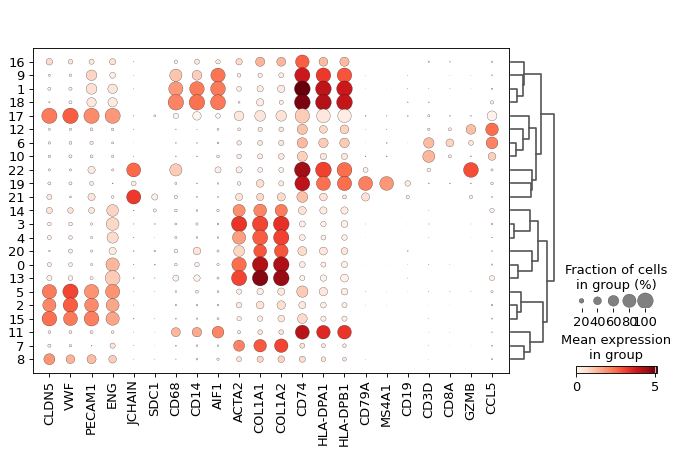

In [20]:
gene_markers = [
                'CLDN5', 'VWF', 'PECAM1','ENG', # Endothelial
                'JCHAIN','SDC1', # Plasma
                'CD68', 'CD14', 'AIF1', # Myeloid
                'ACTA2', 'COL1A1','COL1A2', # Stromal cell
                'CD74','HLA-DPA1','HLA-DPB1', # Dendritic cell
                'CD79A','MS4A1','CD19', # B cell
                'CD3D', 'CD8A', 'GZMB', 'CCL5', # T cell 
                ]

sc.tl.dendrogram(adata_concat, groupby='leiden')
fig, ax = plt.subplots(figsize=(10, 6))
sc.pl.dotplot(adata_concat, groupby='leiden', var_names=gene_markers,
dendrogram=True, use_raw=False, layer='log1p', ax=ax, show=False)

In [21]:
sc.set_figure_params(figsize=(6.5,6))
celltype_mapping_dict = {
    "Stromal cell": [0,3,4,7,13,14,20],
    "Endothelial cell": [2,5,15,17,8],
    "Myeloid cell": [1,9,16,18,22],
    "Dendritic cell":[11],
    "B cell": [19],
    "Plasma cell": [21],
    "T cell": [6,10,12],
}

for k in celltype_mapping_dict:
    lst = celltype_mapping_dict[k]
    celltype_mapping_dict[k] = [str(g) for g in lst]

# Invert the dictionary
cluster_to_cell_type = {cluster: cell_type for cell_type, clusters in celltype_mapping_dict.items() for cluster in clusters}

adata_concat.obs['cell_type'] = pd.Categorical(adata_concat.obs['leiden'].map(cluster_to_cell_type),categories=list(celltype_mapping_dict.keys()))


In [23]:
adata_concat.obs['cell_type'] = adata_concat.obs['cell_type'].replace({'Dendritic cell': 'Myeloid cell'})
ctype_categories = ['Stromal cell', 'Endothelial cell', 'Myeloid cell', 'T cell', 'B cell', 'Plasma cell']
adata_concat.obs['cell_type'] = adata_concat.obs['cell_type'].cat.set_categories(ctype_categories)

### Supplementary figure S3B

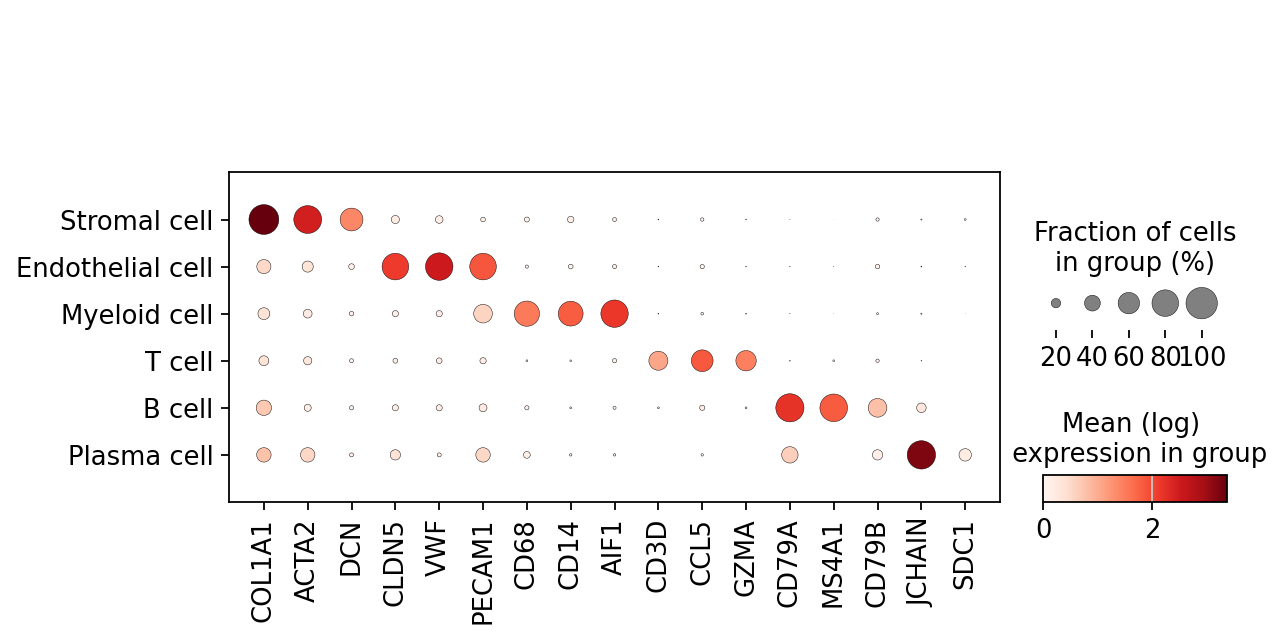

In [24]:
%matplotlib inline
#mpl.use("Agg")

gene_markers = [
                'COL1A1','ACTA2', 'DCN', # Stromal cell
                'CLDN5', 'VWF', 'PECAM1', # Endothelial
                'CD68', 'CD14', 'AIF1', # Myeloid
                'CD3D', 'CCL5','GZMA',  # T cell 
                'CD79A','MS4A1','CD79B', # B cell
                'JCHAIN','SDC1', # Plasma
                ]

fig, ax = plt.subplots(figsize=(8, 4))

sc.pl.DotPlot(adata_concat, groupby='cell_type', var_names=gene_markers,
use_raw=False, layer='log1p', ax=ax).legend(width=2.0).legend(colorbar_title="Mean (log) \n expression in group").show()

#plt.savefig(f'..._{date}.pdf', bbox_inches="tight", dpi=300)
#plt.savefig(f'..._{date}.png', bbox_inches="tight", dpi=300)

### Supplementary figure S3A and 1/4 of Figure 6B

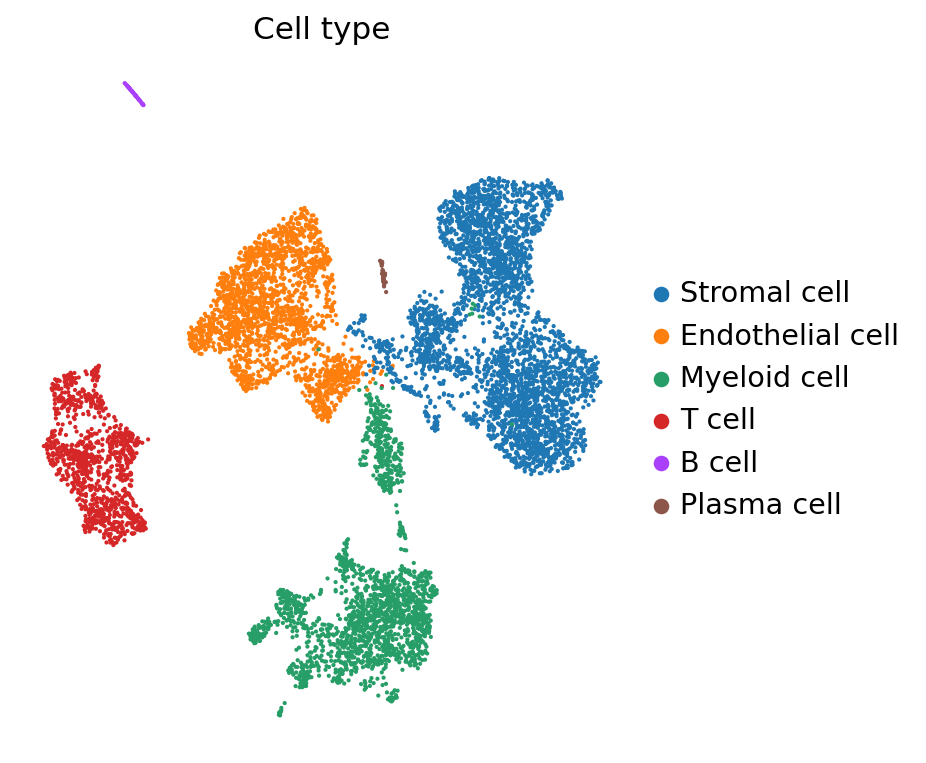

In [25]:
%matplotlib inline
#mpl.use("Agg")

sc.set_figure_params(figsize=(6, 5))
sc.pl.umap(adata_concat, color='cell_type', frameon=False, show=False, save=False)

plt.title("Cell type")

plt.tight_layout()
#plt.savefig(f'.../cell_type_annot_umap_{date}.pdf', bbox_inches="tight", dpi=300)
#plt.savefig(f'.../cell_type_annot_umap_{date}.png', bbox_inches="tight", dpi=300)

### 3/4 of Figure 6B

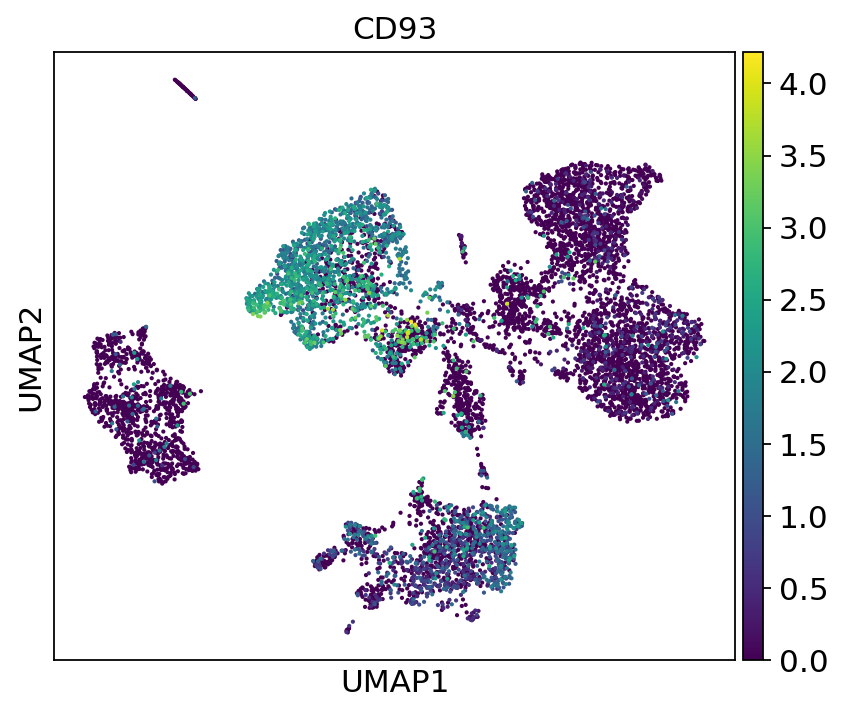

<Figure size 480x400 with 0 Axes>

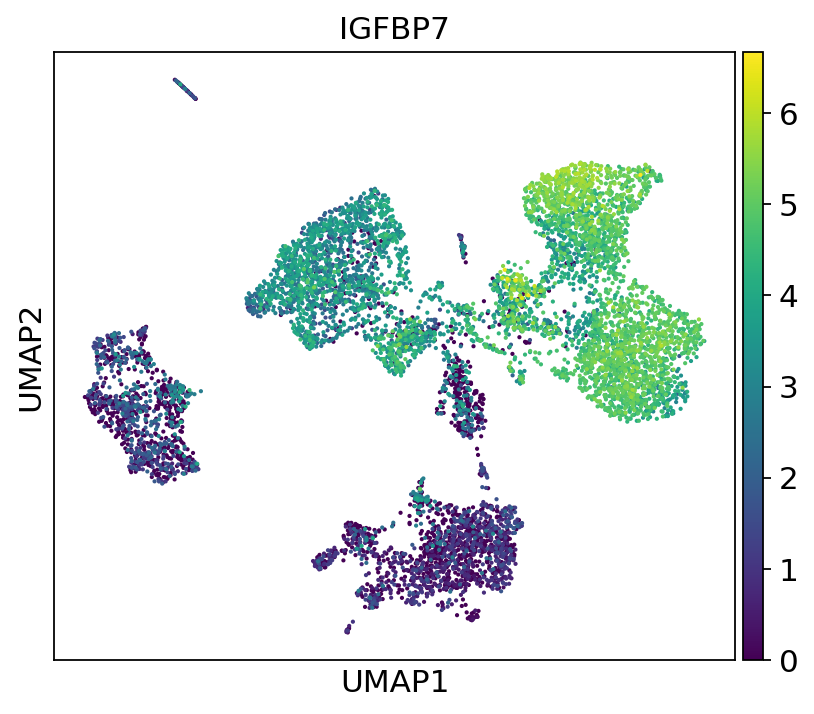

<Figure size 480x400 with 0 Axes>

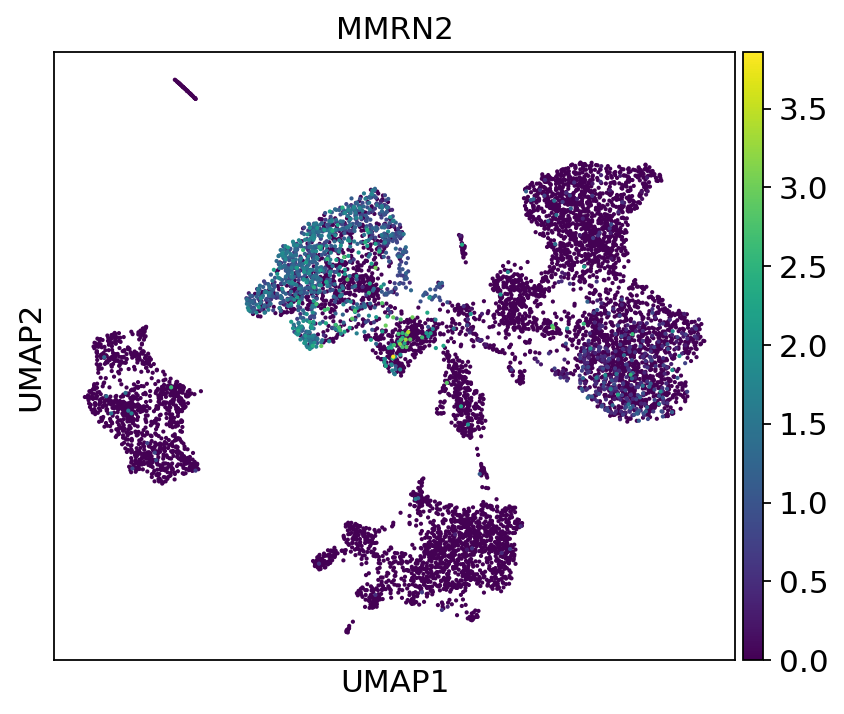

<Figure size 480x400 with 0 Axes>

In [27]:
%matplotlib inline
sc.set_figure_params(figsize=(6, 5))

genes = ["CD93", "IGFBP7", "MMRN2"]

for gene in genes:
    sc.pl.umap(adata_concat, color=gene, frameon=True, show=True, save=False, layer='log1p')

    plt.tight_layout()
    #plt.savefig(f"...")
    plt.show()

### Figure 2A

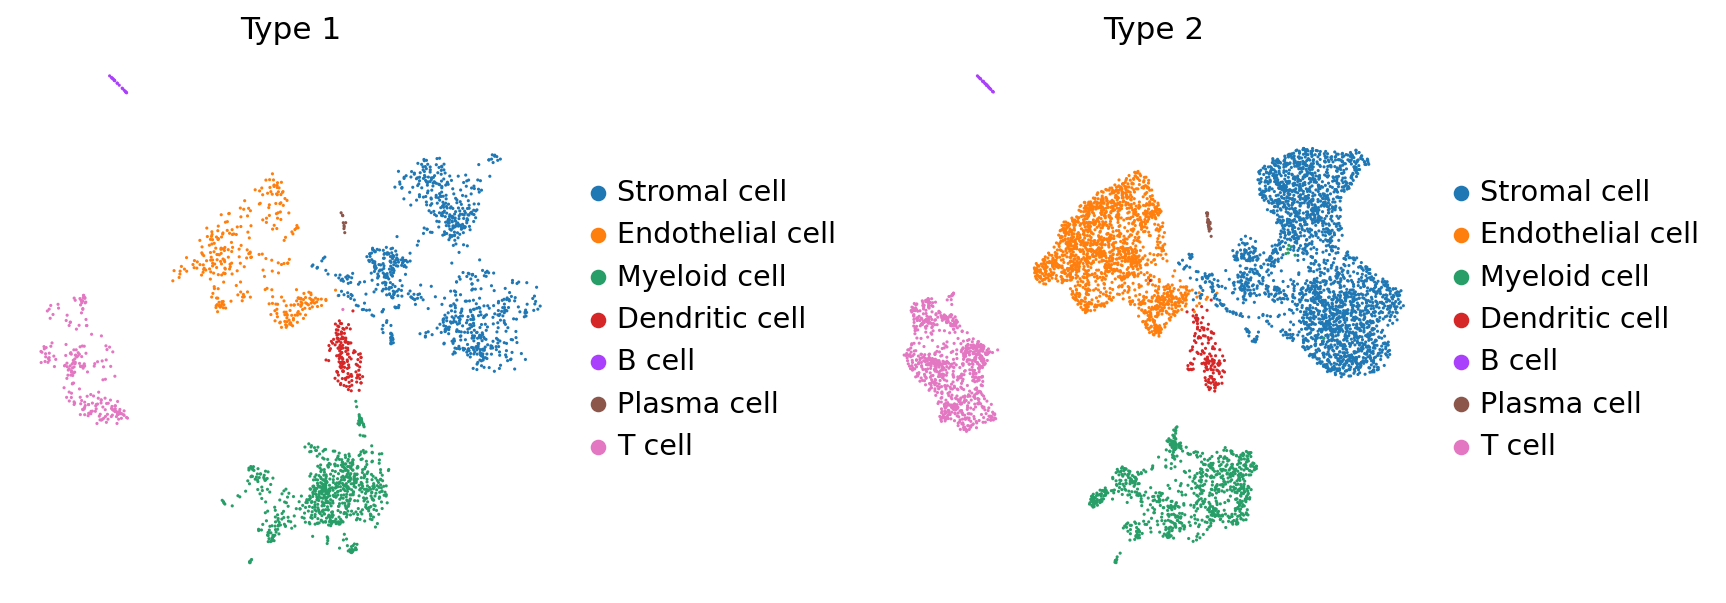

In [17]:
def split_umap(adata, split_by, ncol=2, nrow=None, **kwargs):
    categories = adata.obs[split_by].cat.categories
    if nrow is None:
        nrow = int(np.ceil(len(categories) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5.5*ncol, 4*nrow))
    axs = axs.flatten()
    for i, cat, in enumerate(categories):
        ax = axs[i]
        sc.pl.umap(adata[adata.obs[split_by] == cat], color='cell_type',
        ax=ax, size=8, show=False, frameon=False, title=cat, **kwargs)
    plt.tight_layout()

split_umap(adata_concat, split_by='Diabetes')
plt.tight_layout()
#plt.savefig(f'..._{date}.pdf')
#plt.savefig(f'..._{date}.png')

In [26]:
# Make a copy to avoid modifying the original object unintentionally
adata = adata_concat.copy()
adata.obs_names_make_unique()


# Create an empty column to hold cluster assignments
adata.obs['celltype_leiden'] = None  

# Iterate over all cell types
for ctype in tqdm(adata.obs['cell_type'].unique()):
    print(f'Processing {ctype}...')
    adata_subset = adata[adata.obs['cell_type'] == ctype].copy()
    
    # Compute neighbors and Leiden within this subset
    sc.pp.neighbors(adata_subset, use_rep='X_pca_harmony',random_state=24664712)
    sc.tl.leiden(adata_subset, resolution=0.3, key_added='leiden_tmp')
    
    # Map results back into the main object
    adata.obs.loc[adata_subset.obs_names, 'celltype_leiden'] = (
        ctype + '_' + adata_subset.obs['leiden_tmp'].astype(str)
    )

  0%|          | 0/6 [00:00<?, ?it/s]

Processing Myeloid cell...


 17%|█▋        | 1/6 [00:01<00:09,  1.89s/it]

Processing Stromal cell...


 33%|███▎      | 2/6 [00:04<00:10,  2.59s/it]

Processing T cell...


 50%|█████     | 3/6 [00:05<00:05,  1.79s/it]

Processing Endothelial cell...


100%|██████████| 6/6 [00:07<00:00,  1.30s/it]

Processing B cell...
Processing Plasma cell...


In [27]:
# If the original celltype is less than 1000 cells
# don't do leiden subtype clustering but just copy the label
small_ctype_cats = adata.obs['cell_type'].value_counts()[adata.obs['cell_type'].value_counts() < 1000].index.tolist()
for ctype in small_ctype_cats:
    adata.obs.loc[(adata.obs['cell_type'] == ctype),'celltype_leiden'] = ctype

# Drop cellular subtypes present with < 30 genes
drop_cell_subtypes = adata.obs['celltype_leiden'].value_counts()[adata.obs['celltype_leiden'].value_counts() < 30].index.to_list()

adata = adata[~(adata.obs['celltype_leiden'].isin(drop_cell_subtypes))]
n_types = len(adata.obs['celltype_leiden'].value_counts())
# Summary
print(f'{n_types} unique categories:')
adata.obs['celltype_leiden'].value_counts()

# The subclustering is another possible point of randomness where values may start to deviate


21 unique categories:


celltype_leiden
Stromal cell_0        1564
Stromal cell_1        1272
Myeloid cell_0         957
Endothelial cell_0     828
Endothelial cell_1     545
Stromal cell_2         473
Endothelial cell_2     383
T cell_0               306
T cell_1               301
Dendritic cell         292
Myeloid cell_1         252
T cell_2               224
T cell_3               200
Myeloid cell_2         184
Endothelial cell_3     164
Myeloid cell_3         132
Stromal cell_3         130
Endothelial cell_4      84
Myeloid cell_4          55
B cell                  44
Plasma cell             31
Name: count, dtype: int64

In [ ]:
# Get the unnormalized counts as the x layer
adata.X = adata.raw.X.copy()

#adata.write('./scs_data_clustered_annotated_250611_cellular_subtypes_for_cell2location.h5ad')

In [28]:
"""  
from datetime import datetime
formatted_date = datetime.now().strftime('%y%m%d')
adata_concat.write_h5ad(f'scs_data_clustered_annotated_{formatted_date}.h5ad')
 """

AnnData object with n_obs × n_vars = 8421 × 16245
    obs: 'sample', 'doublet', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'Diabetes', 'cell_type', 'tulehdus/cluster1', 'angiogeneesi/cluster5', 'fibroosi/cluster3', 'fibroosi/cluster4', 'cluster 6', 'celltype_leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Diabetes_colors', 'dendrogram_cell_type', 'dendrogram_leiden', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'log1p'
    obsp: 'connectivities', 'distances'